# Duhamel multidimensional y auditoría final

Sea $S(t)$ el operador solución del problema homogéneo con desplazamiento inicial cero y velocidad inicial $h$. Para

$$
u_{tt}-c^2\Delta u=F(x,t),\qquad u(0)=f,\quad u_t(0)=g,
$$

la solución se escribe

$$
u(t)=C(t)f+S(t)g+\int_0^t S(t-s)F(s)\,ds.
$$

La fórmula separa tres mecanismos: desplazamiento inicial, velocidad inicial y fuerza acumulada. La geometría de $S(t-s)$ determina si cada emisión deja cola: en dimensión tres la respuesta se concentra en esferas; en dos llena discos.

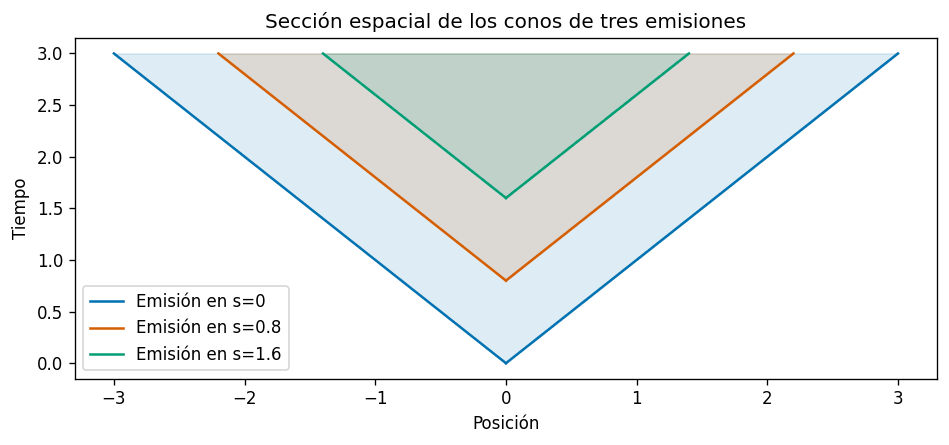

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,3.8))
ax.set(xlabel="Posición",ylabel="Desplazamiento")
for s, color in [(0,"#0072B2"),(0.8,"#D55E00"),(1.6,"#009E73")]:
    t=np.linspace(s,3,180)
    ax.fill_betweenx(t,-(t-s),t-s,color=color,alpha=0.13)
    ax.plot(t-s,t,color=color,label=f"Emisión en s={s:g}")
    ax.plot(s-t,t,color=color)
ax.set(xlabel="Posición",ylabel="Tiempo",title="Sección espacial de los conos de tres emisiones")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
from manim import *

class ConosDeFuentes(Scene):
    def construct(self):
        title = Text("Cada fuente genera su propio cono futuro", font_size=34).to_edge(UP)
        axes = Axes(x_range=[-5, 5, 1], y_range=[0, 6, 1], x_length=9, y_length=5,
                    axis_config={"include_tip": True})
        xlab = Text("espacio", font_size=24).next_to(axes.x_axis, DOWN)
        tlab = Text("tiempo", font_size=24).next_to(axes.y_axis, LEFT)
        source = Dot(axes.c2p(-2, 1), color=YELLOW)
        source_label = Text("emisión en s", font_size=24).next_to(source, RIGHT)
        self.play(FadeIn(title), Create(axes), FadeIn(xlab, tlab), FadeIn(source, source_label))
        self.wait(4)
        self.play(FadeOut(source_label))
        left = Line(axes.c2p(-2, 1), axes.c2p(-5, 4), color=BLUE)
        right = Line(axes.c2p(-2, 1), axes.c2p(3, 6), color=BLUE)
        self.play(Create(left), Create(right), run_time=4)
        for x0, s0 in [(1, 2), (0, 3.2)]:
            dot = Dot(axes.c2p(x0, s0), color=ORANGE)
            cone = VGroup(
                Line(axes.c2p(x0, s0), axes.c2p(x0-(6-s0), 6), color=ORANGE),
                Line(axes.c2p(x0, s0), axes.c2p(x0+(6-s0), 6), color=ORANGE)
            )
            self.play(FadeIn(dot), Create(cone), run_time=3)
        caption = Text("Duhamel integra todas estas respuestas", font_size=27).to_edge(DOWN)
        self.play(FadeIn(caption))
        self.wait(3)

from IPython.display import Video, display

with tempconfig({"pixel_width": 2560, "pixel_height": 1440, "frame_rate": 120,
                 "write_to_movie": True, "format": "mp4", "preview": False}):
    escena = ConosDeFuentes()
    escena.render()
    pelicula = escena.renderer.file_writer.movie_file_path
display(Video(str(pelicula), embed=True))


## Ejercicios esenciales

1. Derive la fórmula abstracta de Duhamel aproximando $F$ por impulsos temporales. Verifique los datos iniciales de la integral forzada.
2. Para una fuerza compactamente soportada en espacio-tiempo, describa el soporte máximo de la solución forzada usando conos causales.

## Auditoría de preparación

- ¿Puedo identificar datos, frontera, dominio y compatibilidad antes de calcular?
- ¿Puedo dibujar el cono pasado de un punto y el cono futuro del soporte?
- ¿Distingo reflexión, separación de variables, energía y Duhamel, y sé cuándo usar cada método?
- ¿Puedo explicar físicamente Huygens y la cola bidimensional?
- ¿Compruebo la ecuación, los datos iniciales y las condiciones de frontera al final?